# The Amery Ice Shelf's Central Terminal Lake: does the shelf sag when it fills?

This notebook runs the tests of [`icesat2_basin_deflection.ipynb`](icesat2_basin_deflection.ipynb) (the Nivlisen basin) on the Amery Ice Shelf's biggest lake. [Spergel et al. (2021, *J. Glaciol.* 67(266), 985–998)](https://doi.org/10.1017/jog.2021.46) call it the **Central Terminal Lake (CTL)**. They do not use the name "Big Lake", but they describe it as the largest ephemeral lake on Amery. From their paper:

* It fills a trough aligned with ice flow in the centre of the shelf, at the downstream end of the central drainage network, between Clemence Massif and the Amery G3 weather station.
* Its median length was ~50 km over 1973–2019, with a maximum of 137 km in February 1992. It forms in most high-melt summers.
* It is shallow. Landsat 8 gives a 99.95th-percentile depth of 1.42 m in 2016/17 and 2.33 m in 2018/19.
* Sentinel-1 shows it freezing through to its bed over about two months after the melt season.

It is a useful contrast with Nivlisen. The shelf here is thicker, so its flexural length is longer. The lake is long but only 1–2 km wide, about one flexural length. A plate should hold such a lake up and spread its sag sideways, unlike the broad, deep Nivlisen lake.

The questions are the same:

1. In which summers of the ICESat-2 era did the lake hold water?
2. What would a plate predict?
3. Where ICESat-2 crossed open water, how does the water surface compare with the water-free surface before filling?
4. What do repeat passes show before and after each fill, and in dry years? Does the change last?

The data helpers are in [`icesat2_tools.py`](icesat2_tools.py). Everything is cached in `outputs/icesat2/`.

### What to expect (from the Nivlisen notebook)

For a lake of depth $d$ whose water is imported, on a surface that does not itself melt:

| | rigid shelf | elastic plate | local isostasy (a relaxed viscoelastic plate) |
|---|---|---|---|
| water surface − surface before, mid-lake | $+d$ | $+(d - w)$ | $+0.03\,d$ |
| bed − surface before | 0 | $-w$ | $-0.97\,d$ |
| water surface − surface before, at the shore | 0 | $-w_{shore} < 0$ | 0 |
| dry ice beyond the shore | 0 | $-w$, decaying over a few $\ell$ | 0 |

Water melted in place adds no load: it only lowers the surface by the volume the snow or firn loses. Water stored in pore space lowers the surface by $0.97\,m/\rho_w$ per kg m$^{-2}$.

## 1. Set-up

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
import plotstyle as ps
from plotstyle import show_map, hillshade
from viscoelastic_beam import IceShelf
from viscoelastic_plate import SpectralPlate
from lake_routing import floating_mask
import icesat2_tools as it

ps.apply()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 170)

BOUNDS = (1840e3, 695e3, 1895e3, 740e3)    # ICESat-2 box (EPSG:3031, m), 55 x 45 km
WIN = (1848e3, 704e3, 1888e3, 726e3)       # Sentinel-2 window, 40 x 22 km
FAR_KM = 7.0                               # far field: > 7 km from any mapped lake
REMA_FILE = "outputs/icesat2/rema_ctl_32m.tif"
if not os.path.exists(REMA_FILE):          # REMA v2 mosaic at 32 m through pdemtools
    import pdemtools as pdt
    pdt.load.mosaic(dataset="rema", resolution=32, bounds=BOUNDS).rio.to_raster(REMA_FILE)
dem = xr.open_dataarray(REMA_FILE, engine="rasterio").squeeze(drop=True).astype(float)
floating = floating_mask(dem)
hs = hillshade(dem.coarsen(x=2, y=2, boundary="trim").mean())
print(f"REMA {dem.sizes['y']} x {dem.sizes['x']} cells of 32 m; {float(floating.mean()):.0%} of the box is floating; "
      f"surface elevation median {float(dem.median()):.0f} m")

REMA 1407 x 1719 cells of 32 m; 99% of the box is floating; surface elevation median 113 m


## 2. The lake through the ICESat-2 era

`it.s2_scan` reads every Sentinel-2 L2A acquisition over the window for each melt season from October 2018 to April 2026. For each one it counts open water (NDWI$_{ice}$ > 0.25 and SWIR < 0.05) and flags cloud (SWIR > 0.12).

276 acquisitions
season
2018     62.8
2019      2.4
2020      0.0
2021      0.0
2022    177.0
2023     16.3
2024     25.6
2025     17.8


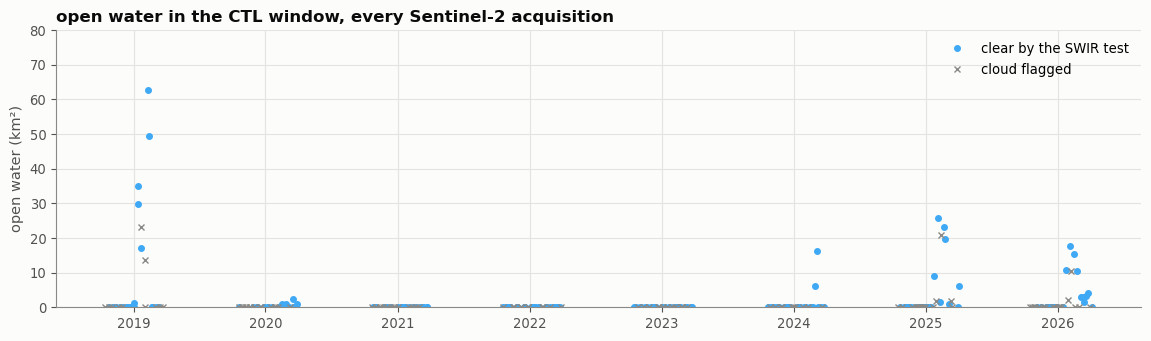

In [2]:
SEASONS = [(f"{y}-10-15", f"{y + 1}-04-15") for y in range(2018, 2026)]
scan, scan_grid = it.s2_scan(WIN, SEASONS, res=40.0, verbose=False)
scan["clear"] = (scan.cloud < 0.3) & (scan.valid > 0.9)
scan["season"] = (scan.date - pd.Timedelta(days=182)).dt.year
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.plot(scan.date[scan.clear], scan.water_km2[scan.clear], "o", ms=4, color=ps.WATER, label="clear by the SWIR test")
ax.plot(scan.date[~scan.clear], scan.water_km2[~scan.clear], "x", ms=4, color=ps.MUTED, label="cloud flagged")
ax.set(ylabel="open water (km²)", title="open water in the CTL window, every Sentinel-2 acquisition", ylim=(0, 80))
ax.legend(loc="upper right")
print(f"{len(scan)} acquisitions")
print(scan[scan.clear].groupby("season").water_km2.max().rename("largest clear-sky water area (km²)").round(1).to_string())

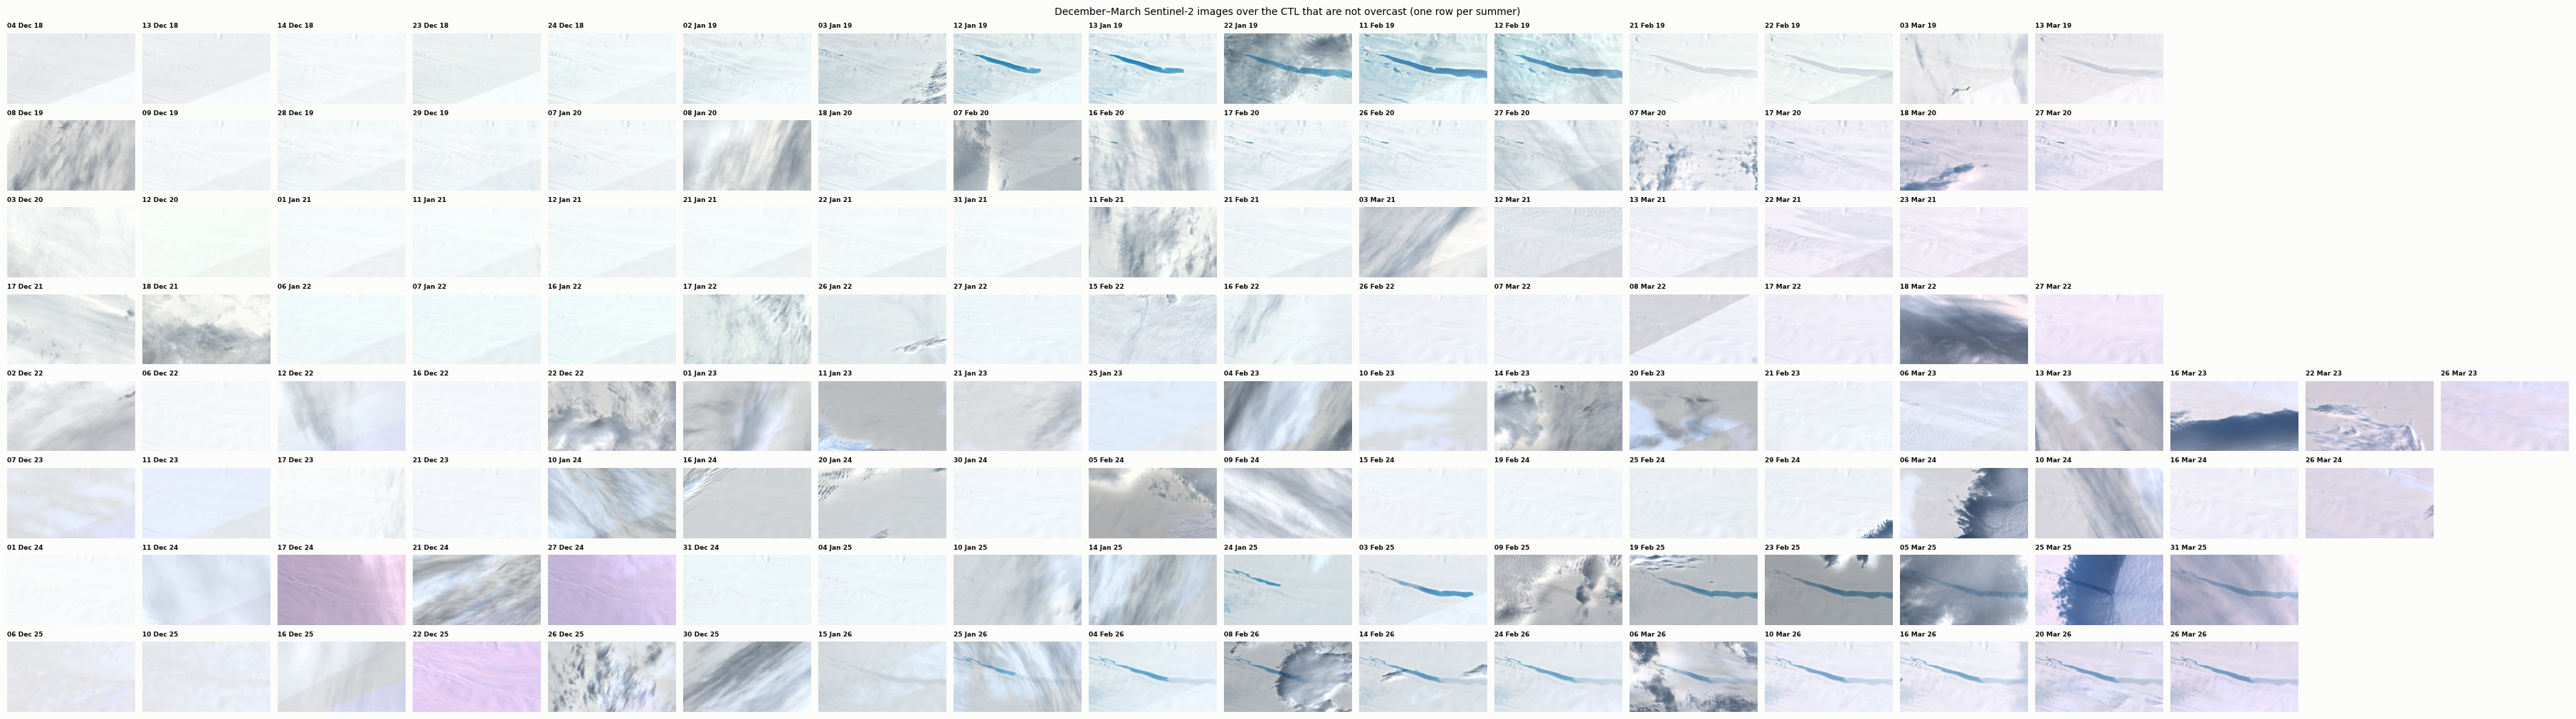

In [3]:
thumbs = scan[scan.date.dt.month.isin([12, 1, 2, 3]) & (scan.valid > 0.5) & (scan.cloud < 0.4)]
seasons = sorted(thumbs.season.unique())
ncol = int(thumbs.groupby("season").size().max())
fig, axs = plt.subplots(len(seasons), ncol, figsize=(1.9 * ncol, 1.25 * len(seasons)), constrained_layout=True)
for row, yr in zip(axs, seasons):
    for ax in row:
        ax.axis("off")
    for ax, (_, r) in zip(row, thumbs[thumbs.season == yr].iterrows()):
        ax.imshow(it.rgb(it.s2_scene(f"{r.date:%Y-%m-%d}", scan_grid, bands=("blue", "green", "red", "swir16"))))
        ax.set_title(f"{r.date:%d %b %y}", fontsize=6.5)
fig.suptitle("December–March Sentinel-2 images over the CTL that are not overcast (one row per summer)", fontsize=10);

**Water in the CTL during the ICESat-2 era: 2019, 2025 and 2026.**

* **2018–19:** a lake ~25 km long from 3–12 January to 12 February 2019, frozen over by 21 February.
* **2019–20:** small, pale patches only.
* **2020–21 to 2023–24:** no lake. The large "water" areas in March 2023 (177 km²) and March 2024 (16 km²) are cloud shadows, as the thumbnails show.
* **2024–25:** a long lake, partly pale (shallow or ice-covered) from late January to the end of March 2025. It reaches past the east edge of the window.
* **2025–26:** a lake from late January to late March 2026, again reaching past the window's east edge.

The lake sits in the same trough each time, but its extent and shape change from year to year.

2019-01-13: lake 34.2 km² inside the window
2025-02-19: lake 41.0 km² inside the window
2026-02-14: lake 21.6 km² inside the window
trough axis points 166° from +x (EPSG:3031)


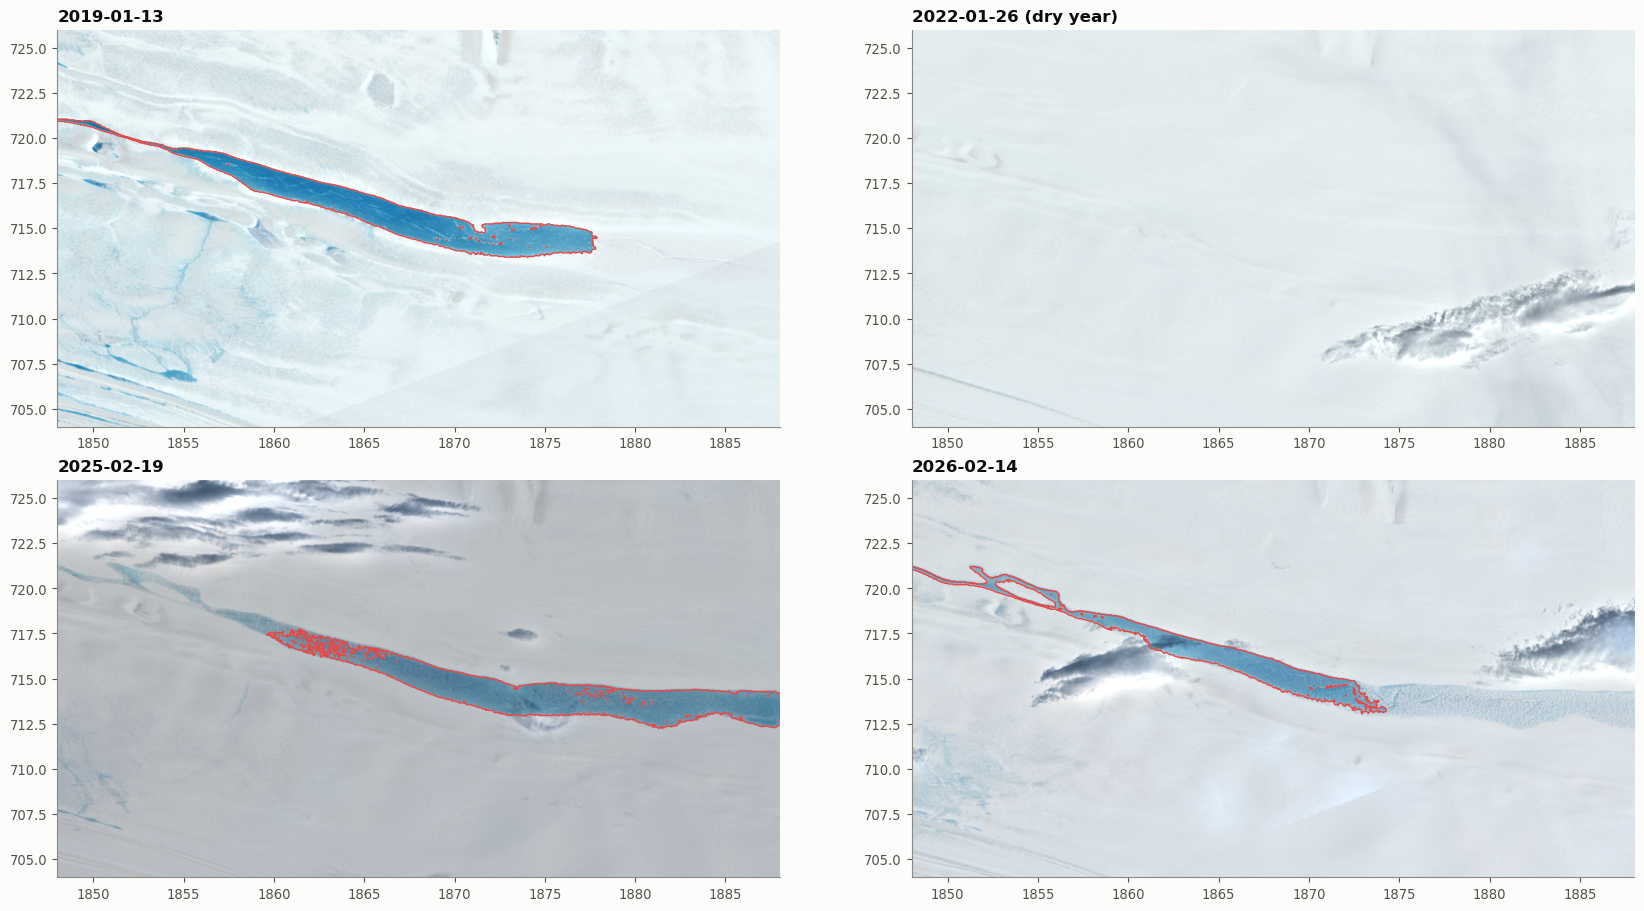

In [4]:
KEY = {"2019": "2019-01-13", "2022": "2022-01-26", "2025": "2025-02-19", "2026": "2026-02-14"}
scenes = {yr: it.s2_scene(d, scan_grid, bands=("blue", "green", "red", "swir16")) for yr, d in KEY.items()}
# the lake: largest connected area with NDWI_ice > 0.15 (pale, shallow parts of the CTL fall below 0.25)
lakes = {yr: it.lake_mask(it.ndwi_ice(s), None, thresh=0.15) for yr, s in scenes.items() if yr != "2022"}
for yr, m in lakes.items():
    print(f"{KEY[yr]}: lake {float(m.sum()) * 1600 / 1e6:.1f} km² inside the window")

# the trough's axis from the 2019 lake: cross-axis distance n, along-axis distance a
yy, xx = np.nonzero(lakes["2019"].values)
AX = it.track_frame(lakes["2019"].x.values[xx], lakes["2019"].y.values[yy])
def axis_coords(x, y):
    o, u = AX
    dx, dy = np.asarray(x) - o[0], np.asarray(y) - o[1]
    return dx * u[0] + dy * u[1], -dx * u[1] + dy * u[0]          # (along, across)
print(f"trough axis points {np.degrees(np.arctan2(AX[1][1], AX[1][0])):.0f}° from +x (EPSG:3031)")

# far field: more than FAR_KM from any mapped lake (a KD-tree over all lake pixels)
lake_pts = np.vstack([np.c_[m.x.values[np.nonzero(m.values)[1]], m.y.values[np.nonzero(m.values)[0]]] for m in lakes.values()])
lake_tree = cKDTree(lake_pts)
def far(d):
    return pd.Series(lake_tree.query(np.c_[d.x, d.y])[0] > FAR_KM * 1e3, index=d.index) & (d.dgl > 3e3)

fig, axs = plt.subplots(2, 2, figsize=(17, 9), constrained_layout=True)
ext = ps.map_extent(scan_grid)
for ax, (yr, s) in zip(axs.flat, scenes.items()):
    ax.imshow(it.rgb(s), extent=ext)
    if yr in lakes:
        ax.contour(scan_grid.x / 1e3, scan_grid.y / 1e3, lakes[yr].astype(float), [0.5], colors=ps.TENSION, linewidths=1)
    ax.set_title(f"{KEY[yr]}" + ("" if yr in lakes else " (dry year)"))
    ax.set_aspect("equal"); ax.grid(False)

## 3. ICESat-2 over the lake

In [5]:
atl = it.fetch_atl06(BOUNDS)
atl = atl[atl.atl06_quality_summary == 0]
atl = it.add_reference(atl, dem, floating)
atl["along"], atl["across"] = axis_coords(atl.x, atl.y)
print(f"{len(atl):,} good ATL06 segments on {atl.rgt.nunique()} reference ground tracks, "
      f"{atl.time.min():%d %b %Y} to {atl.time.max():%d %b %Y}")

def in_lake(df, yr, buffer_m=0.0):
    m = lakes[yr]
    if buffer_m:
        m = m.copy(data=ndi.binary_dilation(m.values, iterations=int(buffer_m // 40)))
    return m.sel(x=xr.DataArray(df.x.values), y=xr.DataArray(df.y.values), method="nearest").values & \
        df.x.between(WIN[0], WIN[2]).values & df.y.between(WIN[1], WIN[3]).values

rows = []
for yr in lakes:
    t0, t1 = pd.Timestamp(f"{int(yr) - 1}-12-01"), pd.Timestamp(f"{yr}-03-31")
    sub = atl[atl.time.between(t0, t1)]
    hit = sub[in_lake(sub, yr)]
    for (rgt, cyc), q in hit.groupby(["rgt", "cycle"]):
        rows.append(dict(lake=yr, rgt=rgt, cycle=cyc, date=f"{q.time.iloc[0]:%Y-%m-%d}", segments_in_lake=len(q),
                         beams=",".join(map(str, sorted(q.beam.unique())))))
pd.DataFrame(rows).sort_values("date")

3,807,842 good ATL06 segments on 16 reference ground tracks, 28 Oct 2018 to 18 Jul 2026


,lake,rgt,cycle,date,segments_in_lake,beams
4,2019,973,1,2018-12-01,615,"10,20,30,40,50,60"
0,2019,28,2,2018-12-30,251,"10,20"
1,2019,462,2,2019-01-27,475,"10,20,30,40,50,60"
2,2019,531,2,2019-02-01,287,"10,20,30,40,50,60"
3,2019,904,2,2019-02-25,874,"30,40,50,60"
5,2019,973,2,2019-03-02,659,"10,20,30,40,50,60"
8,2025,1346,25,2024-12-13,114,"50,60"
6,2025,28,26,2024-12-17,850,"10,20,30,40,50,60"
7,2025,973,26,2025-02-17,558,"10,20,30,40,50,60"
9,2025,1346,26,2025-03-14,193,"50,60"


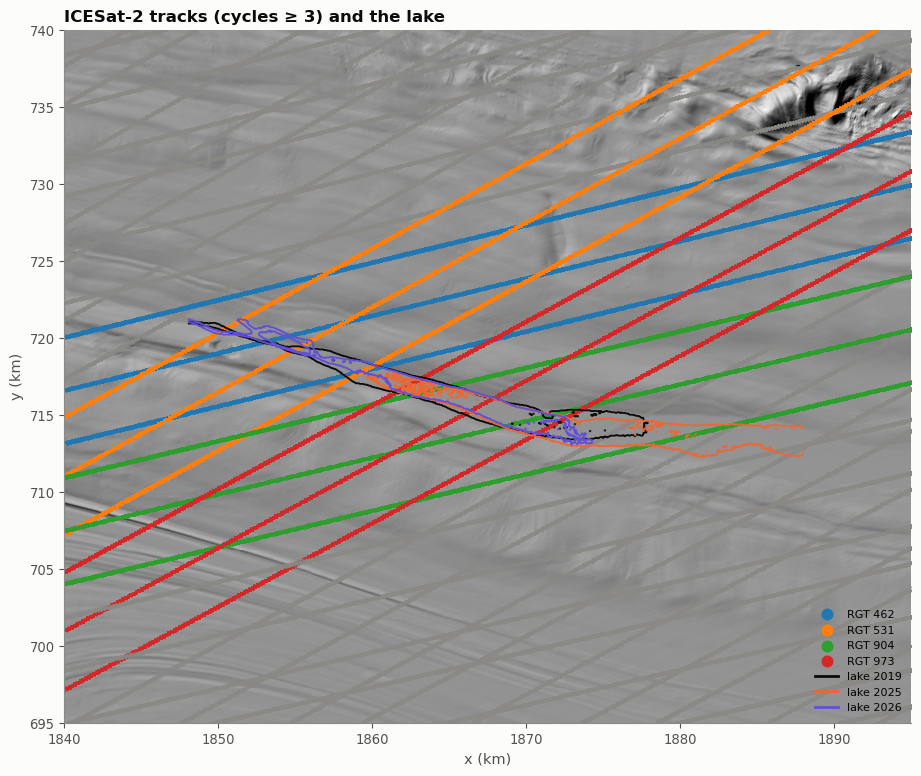

In [6]:
fig, ax = plt.subplots(figsize=(12, 9))
show_map(ax, hs, "ICESat-2 tracks (cycles ≥ 3) and the lake", cmap="gray", vmin=0, vmax=1)
sub = atl[(atl.cycle >= 3) & (atl.segment_id % 10 == 0)]
for rgt, q in sub.groupby("rgt"):
    hl = rgt in (462, 531, 904, 973)
    ax.scatter(q.x / 1e3, q.y / 1e3, s=0.4 if hl else 0.15, color=None if hl else ps.MUTED, rasterized=True,
               label=f"RGT {rgt}" if hl else None)
for yr, c in zip(lakes, [ps.INK, ps.ELASTIC, ps.ACCENT]):
    ax.contour(scan_grid.x / 1e3, scan_grid.y / 1e3, lakes[yr].astype(float), [0.5], colors=c, linewidths=1.3)
    ax.plot([], [], color=c, label=f"lake {yr}")
ax.set(xlim=(BOUNDS[0] / 1e3, BOUNDS[2] / 1e3), ylim=(BOUNDS[1] / 1e3, BOUNDS[3] / 1e3))
ax.legend(loc="lower right", markerscale=12, fontsize=8);

Four tracks cross the lake obliquely: RGTs 462, 531, 904 and 973. RGT 973 is the most useful: all six beams cross the lake, it has passes in late November–early December and late February most years, and its first pass (1 December 2018) came a month before the 2019 lake appeared.

## 4. What a plate predicts for the CTL

The ice here is thicker than on Nivlisen. If the surface is in hydrostatic balance, $H \approx \rho_{sw}(s - 15)/(\rho_{sw} - \rho_i)$, allowing ~15 m of firn air. REMA heights are above the ellipsoid, not the geoid, so this overestimates $H$ by about nine times the geoid height. Both flexural lengths below are therefore upper bounds. The load is the 2019 lake mapped above, with a bowl-shaped depth that peaks at 2.33 m (Spergel et al.'s 99.95th percentile for 2018/19). Two elastic plates bear it, one with $E$ = 1 GPa and one with the softer modulus that the Nivlisen tidal flexure suggests, alongside local isostasy. Because the lake is long and straight, the sag is shown against distance across the trough axis.

surface ~110 m, so H ~ 879 m; lake load 42.9 Mm³, mean depth 1.25 m, width ~1.6 km
   elastic, E = 1 GPa (ell = 1576 m): sag mid-lake 0.44 m (24% of isostatic); at 1 km beyond the shore 0.31 m
 elastic, E = 0.2 GPa (ell = 1054 m): sag mid-lake 0.63 m (35% of isostatic); at 1 km beyond the shore 0.32 m
                           isostatic: sag mid-lake 1.80 m (100% of isostatic); at 1 km beyond the shore 0.00 m


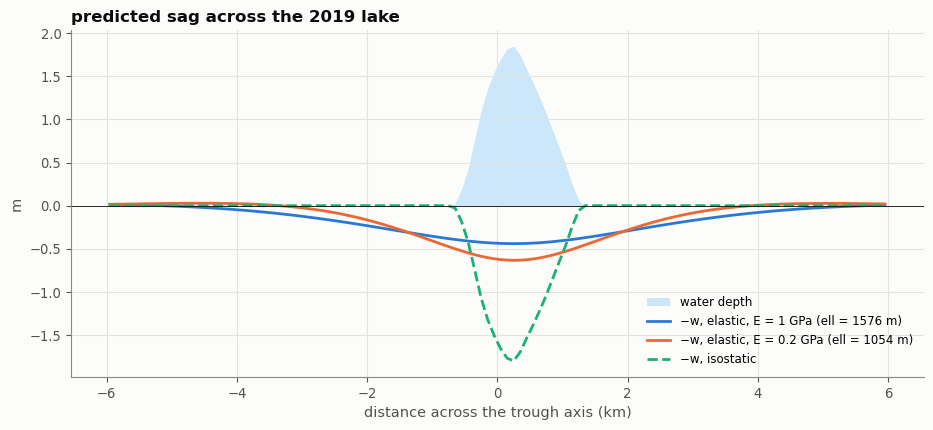

In [7]:
s_lake = float(dem.where(floating).sel(x=slice(1850e3, 1880e3), y=slice(722e3, 708e3)).median())
H = 1028 * (s_lake - 15) / (1028 - 917)
DMAX = 2.33
m19 = lakes["2019"].values
dist = ndi.distance_transform_edt(m19) * 40.0
depth = DMAX * (1 - (1 - dist / dist.max()) ** 2) * m19
pad = 250
dep_p = np.pad(depth, pad)
gx = np.r_[scan_grid.x.values[0] - 40 * np.arange(pad, 0, -1), scan_grid.x.values, scan_grid.x.values[-1] + 40 * np.arange(1, pad + 1)]
gy = np.r_[scan_grid.y.values[0] + 40 * np.arange(pad, 0, -1), scan_grid.y.values, scan_grid.y.values[-1] - 40 * np.arange(1, pad + 1)]
q = it.RHO_W * it.G * dep_p
PLATES = {f"elastic, E = 1 GPa (ell = {it.flexural_length(1e9, H):.0f} m)": 1e9,
          f"elastic, E = 0.2 GPa (ell = {it.flexural_length(2e8, H):.0f} m)": 2e8}
wpred = {name: xr.DataArray(SpectralPlate(gx.size, gy.size, 40.0, IceShelf(H=H, E=E), x=gx, y=gy).elastic(q),
                            coords={"y": gy, "x": gx}, dims=("y", "x")) for name, E in PLATES.items()}
wpred["isostatic"] = xr.DataArray(it.RHO_W / it.RHO_SW * dep_p, coords={"y": gy, "x": gx}, dims=("y", "x"))
depth_da = xr.DataArray(dep_p, coords={"y": gy, "x": gx}, dims=("y", "x"))
print(f"surface ~{s_lake:.0f} m, so H ~ {H:.0f} m; lake load {depth.sum() * 1600 / 1e6:.1f} Mm³, mean depth "
      f"{depth[m19].mean():.2f} m, width ~{2 * dist.max() / 1e3:.1f} km")

# cross-trough profiles, averaged over the middle half of the lake's length
GX, GY = np.meshgrid(gx, gy)
A_, N_ = axis_coords(GX, GY)
la = A_[np.pad(m19, pad)]
mid = (A_ > np.percentile(la, 25)) & (A_ < np.percentile(la, 75))
nb = np.arange(-6000, 6001, 100.0)
def across_profile(field):
    idx = np.digitize(N_[mid], nb)
    v = np.asarray(field)[mid]
    return np.array([v[idx == k].mean() if (idx == k).any() else np.nan for k in range(1, nb.size)])
nc = 0.5 * (nb[1:] + nb[:-1])
dprof = across_profile(dep_p)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(nc / 1e3, 0, dprof, color=ps.WATER, alpha=0.25, lw=0, label="water depth")
for (name, w), c, ls in zip(wpred.items(), [ps.VISCO, ps.ELASTIC, ps.ISO], ["-", "-", "--"]):
    ax.plot(nc / 1e3, -across_profile(w), color=c, ls=ls, label=f"−w, {name}")
ax.axhline(0, color=ps.INK, lw=0.6)
ax.set(xlabel="distance across the trough axis (km)", ylabel="m", title="predicted sag across the 2019 lake")
ax.legend(fontsize=8.5, loc="lower right")
for name, w in wpred.items():
    p = across_profile(w)
    print(f"{name:>36}: sag mid-lake {np.nanmax(p):.2f} m ({np.nanmax(p) / (0.973 * np.nanmax(dprof)):.0%} of isostatic); "
          f"at 1 km beyond the shore {p[np.argmin(abs(nc - (dist.max() + 1000)))]:.2f} m")

For this narrow lake the plate matters. An elastic plate carries most of the load sideways: the ice under the lake sinks by only a quarter to a third of the isostatic amount. The ice beside it sinks instead, by ~0.3 m 1 km beyond the shore for a 2.3 m deep lake, and the sag reaches a few kilometres out. Over the water, the plates therefore predict a water surface that stands above the old surface by $d - w$, two thirds or more of the depth. Local isostasy (a fully relaxed plate) predicts only $+0.03\,d$ and no sag beside the lake.

## 5. The water surface against the water-free surface before filling

ICESat-2 crossed open water in the CTL on several dates (Section 3). Three crossings have a water-free pass on the same track beforehand:

| summer | over open water | water-free reference |
|---|---|---|
| 2025 | RGT 973, 17 Feb 2025 | RGT 973, 20 Aug 2024 |
| 2026 | RGT 904, 11 Feb 2026 | RGT 904, 13 Aug 2025 |
| 2026 | RGT 973, 16 Feb 2026 | RGT 973, 18 Aug 2025 |

The 27 January 2019 pass of RGT 462 also crossed open water, but its only earlier pass, in cycle 1, lies too far from it to pair. The August references are winter surfaces. For 2026 they lie on the frozen remains of the 2025 lake. Spergel et al. found the lake freezes through, so its mass is still there in August, and only water added in the new summer is a new load. The plate predictions use the water depth that ATL03 measures along each crossing. The 1-D beam is applied across the trough, with along-track distance scaled by the sine of the angle at which the track crosses the trough.

In [8]:
WET = [("2025", 973, 26, 24, "2025-02-17"),
       ("2026", 904, 30, 28, "2026-02-11"), ("2026", 973, 30, 28, "2026-02-16")]
res, store = [], {}
for yr, rgt, cw, cr, day in WET:
    a6 = atl[(atl.rgt == rgt) & (atl.cycle == cw)]
    hit = a6[in_lake(a6, yr, buffer_m=200)]
    for spot, q in hit.groupby("spot"):
        if len(q) < 10:
            continue
        # photons within 4 km of where this beam crosses the lake (rounded so the cache key is stable)
        box = tuple(float(v) for v in (np.floor(q.x.min() / 1e3 - 4) * 1e3, np.floor(q.y.min() / 1e3 - 4) * 1e3,
                                       np.ceil(q.x.max() / 1e3 + 4) * 1e3, np.ceil(q.y.max() / 1e3 + 4) * 1e3))
        ph = it.fetch_atl03(box, day, rgt)
        if spot not in ph.spot.unique():
            continue
        try:
            sb, sm = it.wet_crossing(atl, ph, rgt, cw, cr, spot, dem, far, (q.y.min(), q.y.max()), tol=0.15)
        except Exception as e:
            print(f"{day} RGT {rgt} spot {spot}: skipped ({type(e).__name__})")
            continue
        if sm["length_km"] < 0.3:
            continue
        # angle between the track and the trough axis, to map along-track distance onto distance across the trough
        o, u = it.track_frame(ph[ph.spot == spot].x, ph[ph.spot == spot].y)
        sm["stretch"] = abs(u[0] * AX[1][1] - u[1] * AX[1][0])
        sm["year"] = yr
        res.append(sm)
        store[(day, rgt, spot)] = (ph, sb, sm)
wtab = pd.DataFrame(res)
cols = ["year", "wet", "ref", "rgt", "spot", "length_km", "water_level", "level_minus_floor", "level_minus_shore_south",
        "level_minus_shore_north", "bed_fraction", "depth_median", "depth_max", "floor_drop", "sep_m", "stretch"]
wtab[cols].round(2)

/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,year,wet,ref,rgt,spot,length_km,water_level,level_minus_floor,level_minus_shore_south,level_minus_shore_north,bed_fraction,depth_median,depth_max,floor_drop,sep_m,stretch
0,2025,2025-02-17,2024-08-20,973,1,1.80,99.23,0.13,-0.49,-0.99,0.13,1.88,2.47,1.72,39.93,0.67
1,2025,2025-02-17,2024-08-20,973,2,1.76,99.30,0.10,-0.27,-0.77,0.00,NaN,NaN,NaN,28.84,0.67
2,2025,2025-02-17,2024-08-20,973,3,1.88,99.35,0.32,-0.22,-0.74,0.13,1.75,2.05,1.32,4.45,0.67
3,2025,2025-02-17,2024-08-20,973,4,1.92,99.38,0.33,-0.16,-1.25,0.02,1.92,1.92,1.85,9.34,0.67
4,2025,2025-02-17,2024-08-20,973,5,2.52,99.46,0.06,-0.34,-0.27,0.00,NaN,NaN,NaN,31.48,0.67
5,2025,2025-02-17,2024-08-20,973,6,2.48,99.50,0.06,-0.24,-0.39,0.02,1.76,1.76,1.71,25.68,0.67
6,2026,2026-02-11,2025-08-13,904,3,3.00,99.30,0.26,0.26,0.04,0.00,NaN,NaN,NaN,15.63,0.46
7,2026,2026-02-11,2025-08-13,904,4,3.36,99.29,0.30,-0.12,-0.05,0.01,2.18,2.18,1.85,10.01,0.46
8,2026,2026-02-11,2025-08-13,904,5,2.80,99.13,0.28,-0.08,-0.07,0.00,NaN,NaN,NaN,15.16,0.46
9,2026,2026-02-11,2025-08-13,904,6,2.48,99.14,0.30,0.31,-0.41,0.03,3.30,4.24,2.99,13.45,0.46


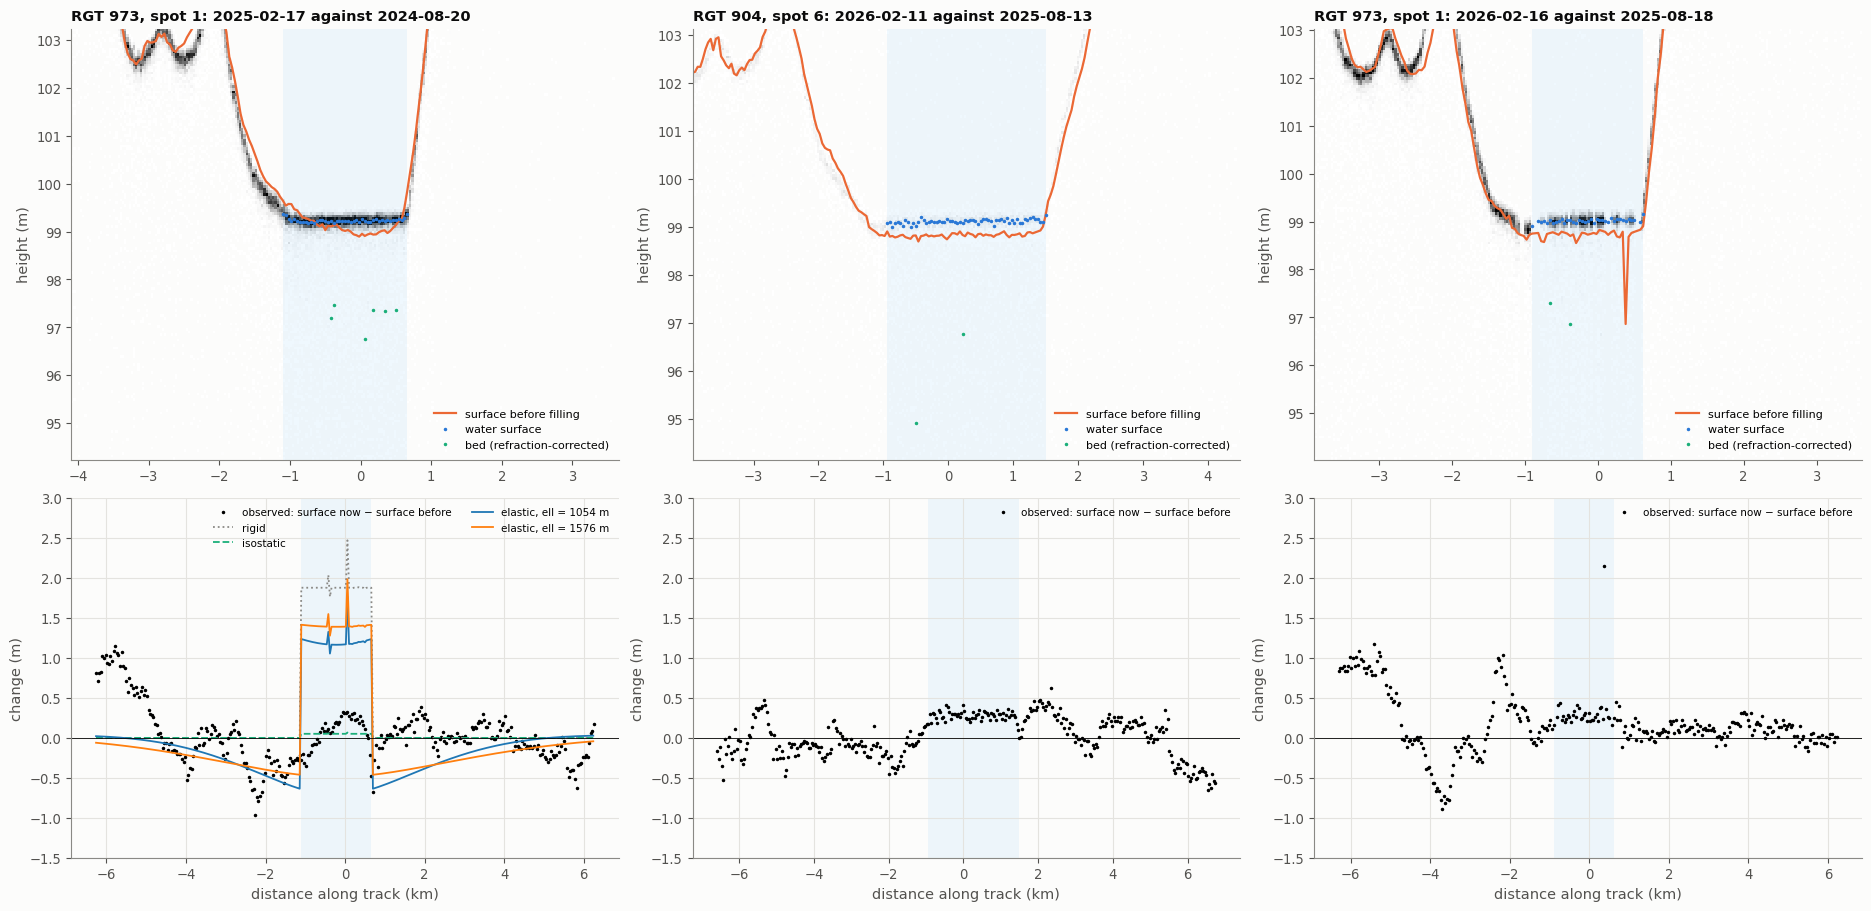

In [9]:
# one figure per crossing date: the beam on which ATL03 sees the most lake bed
picks = (wtab.assign(score=lambda d: d.bed_fraction + 0.01 * d.length_km)
         .sort_values("score", ascending=False).groupby(["wet", "rgt"]).head(1).sort_values("wet"))
fig, axs = plt.subplots(2, len(picks), figsize=(6.2 * len(picks), 9), gridspec_kw=dict(height_ratios=[1.2, 1]),
                        constrained_layout=True, squeeze=False)
for col, (_, r) in enumerate(picks.iterrows()):
    ph, sb, sm = store[(r.wet, r.rgt, r.spot)]
    ells = tuple(round(it.flexural_length(E, H)) for E in (2e8, 1e9))
    has_bed = sb[sb.water].bed.notna().sum() >= 3
    cp = it.crossing_predictions(sb, sm, ells=ells, stretch=sm["stretch"], fill="median") if has_bed else None
    it.plot_crossing(axs[:, col], ph, sb, sm, pred=cp, hlim=(sm["water_level"] - 5, sm["water_level"] + 4))
    w = sb[sb.water]
    axs[0, col].set_title(f"RGT {r.rgt}, spot {r.spot}: {sm['wet']} against {sm['ref']}", fontsize=10.5)
    axs[0, col].set_xlim(w.s.min() / 1e3 - 3, w.s.max() / 1e3 + 3)
    axs[1, col].set_ylim(-1.5, 3)

In [10]:
summ = wtab[wtab.length_km > 0.5].groupby("wet").agg(
    beams=("spot", "size"), water_level_minus_floor=("level_minus_floor", "median"),
    minus_shore_south=("level_minus_shore_south", "median"), minus_shore_north=("level_minus_shore_north", "median"),
    depth=("depth_median", "median"), floor_drop=("floor_drop", "median"))
summ.round(2)

,beams,water_level_minus_floor,minus_shore_south,minus_shore_north,depth,floor_drop
wet,,,,,,
2025-02-17,6,0.11,-0.25,-0.76,1.82,1.71
2026-02-11,4,0.29,0.09,-0.06,2.74,2.42
2026-02-16,6,0.33,-0.17,-0.39,1.94,1.64


Along every crossing the water is a flat sheet on the trough floor, bounded by its steep walls. Where ATL03 sees a bed (in a few bins only), the water is ~1.8–2.7 m deep. Each panel shows the beam with the most bed returns. Where at least three bins have a bed (the 2025 crossing), the thin lines in the bottom row put that median depth across the whole water crossing.

* **The water surface stands only 0.1–0.35 m above the winter surface it replaced** (medians over the beams: +0.11 m in 2025, +0.29 and +0.33 m in 2026). That holds even though the lake is ~2 m deep, so the floor is now 1.6–2.4 m below the winter surface.
* **For new water, that is the isostatic answer.** A rigid shelf would put the water surface ~2 m above the old surface. An elastic plate, which for this narrow lake carries most of the load sideways, would put it 1.3–1.5 m above, and it would dip the walls. Local isostasy gives ~+0.06 m.
* **The walls tell us little.** In 2025 the south flank is 0.5–0.9 m lower within 2 km of the shore. That is the size of the elastic plates' flank sag, but the north flank shows nothing similar, and dry years have ±0.5 m features at these distances too (Section 6).
* **But the floor need not have sunk.** The trough floor holds the frozen lake of earlier summers under snow: 2025's for the 2026 crossings, and 2019's, advected and buried, for 2025. Melting that ice and snow in place lowers the surface without adding any load. So the "floor drop" here can be melt of the old lake's lid, not sinking. The surface ending up close to where it was is what the lake melting out in place would do.

So at the CTL the water-surface test cannot tell sinking from melting in place. The sag beside the lake (Section 6) is the better test.

## 6. Fill events and dry years

Repeat-pass differences across the trough, with the far-field median removed. Distance is measured across the trough axis, so every beam that crosses the lake falls on one profile.

In [11]:
EVENTS = [("2025 lake", 973, 24, 26), ("2025 lake", 904, 25, 27),
          ("2026 lake", 973, 28, 30), ("2026 lake", 904, 28, 30),
          ("dry 2021–22", 973, 13, 14), ("dry 2022–23", 904, 17, 18), ("dry 2023–24", 904, 21, 22), ("dry 2023–24", 973, 21, 22)]
ev, erows = {}, []
for name, rgt, ca, cb in EVENTS:
    d = it.pass_difference(atl, rgt, ca, cb, max_sep=600, far=far)
    if len(d) == 0:
        continue
    d["along"], d["across"] = axis_coords(d.x, d.y)
    d = d[d.dgl > 1500]
    ev[(name, rgt)] = d
    near = d[d.along.between(-15e3, 15e3)]
    erows.append(dict(event=name, rgt=rgt, before=f"{d.time_ref.iloc[0]:%Y-%m-%d}", after=f"{d.time.iloc[0]:%Y-%m-%d}",
                      sep_m=d.sep.median(), far_sd_m=d[d.far].dh.std(),
                      in_trough=near[near.across.abs() < 700].dh.median(),
                      beside_1_3km=near[near.across.abs().between(1000, 3000)].dh.median(),
                      p05_within_4km=near[near.across.abs() < 4000].dh.quantile(0.05)))
etab = pd.DataFrame(erows)
etab.round(2)

,event,rgt,before,after,sep_m,far_sd_m,in_trough,beside_1_3km,p05_within_4km
0,2025 lake,973,2024-08-20,2025-02-17,26.29,0.28,0.02,-0.10,-0.52
1,2025 lake,904,2024-11-14,2025-05-15,10.12,0.26,-0.06,-0.20,-0.71
2,2026 lake,973,2025-08-18,2026-02-16,7.17,0.35,0.23,0.04,-0.43
3,2026 lake,904,2025-08-13,2026-02-11,9.92,0.21,0.19,-0.01,-0.52
4,dry 2021–22,973,2021-11-25,2022-02-24,6.74,0.19,0.01,0.10,-0.27
5,dry 2022–23,904,2022-11-18,2023-02-17,2.75,0.14,-0.01,-0.08,-0.32
6,dry 2023–24,904,2023-11-17,2024-02-16,9.88,0.72,0.01,-0.04,-0.33
7,dry 2023–24,973,2023-11-21,2024-02-20,5.82,0.25,-0.03,0.01,-0.25


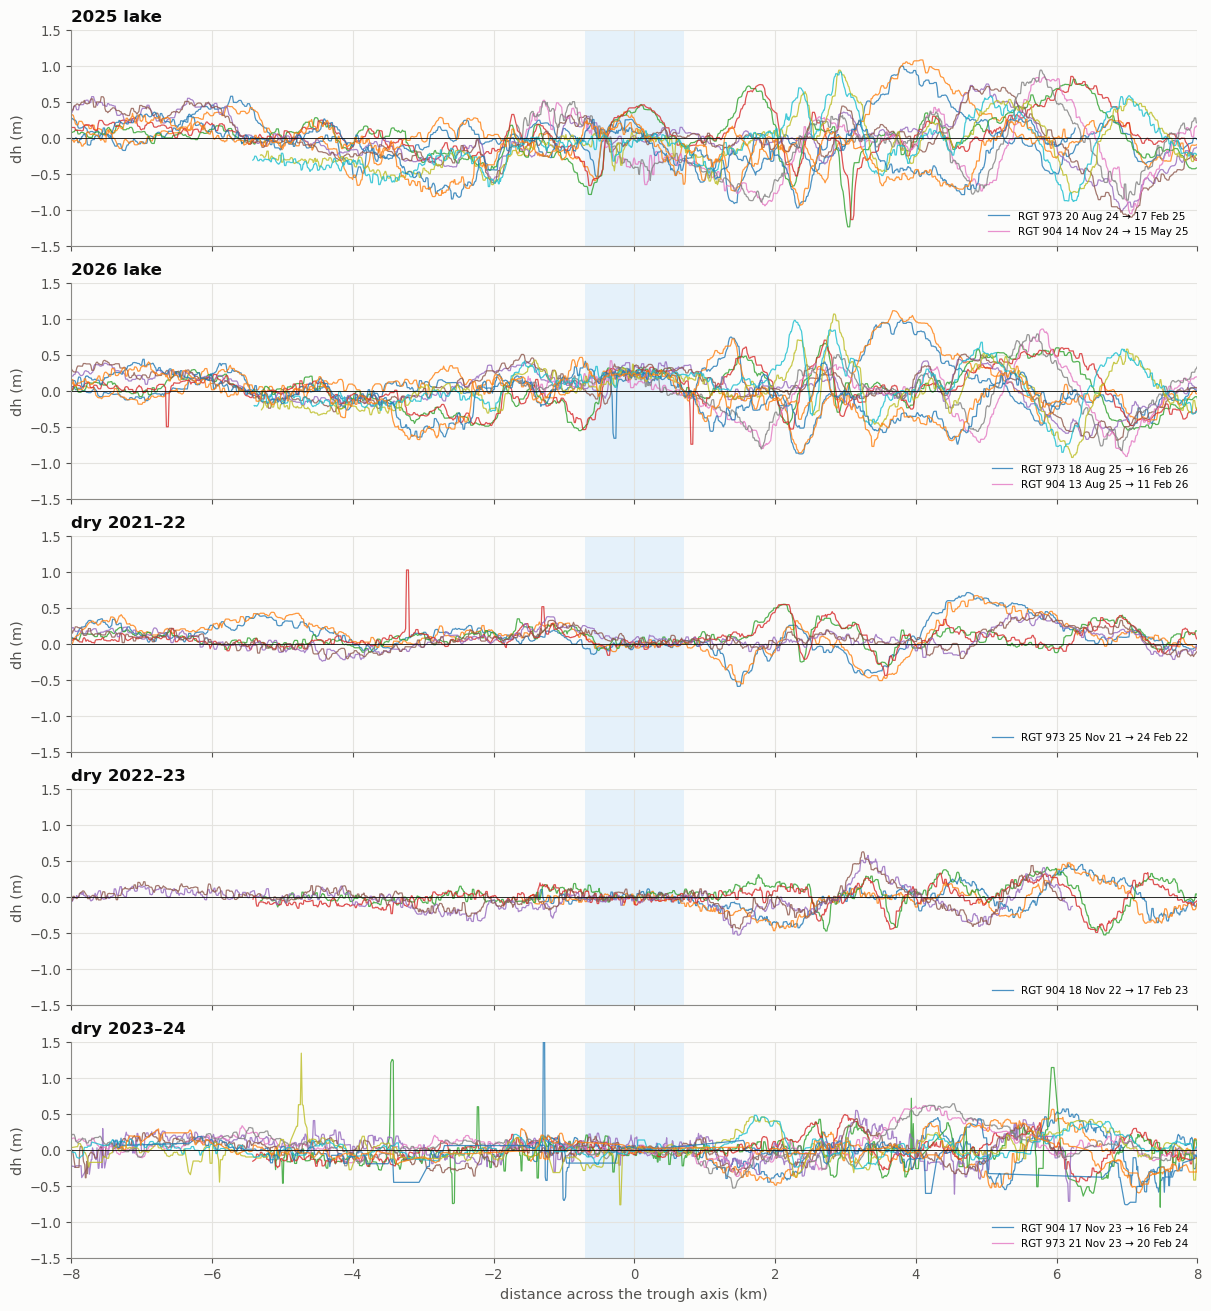

In [12]:
names = list(dict.fromkeys(n for n, _ in ev))
fig, axs = plt.subplots(len(names), 1, figsize=(12, 2.6 * len(names)), sharex=True, constrained_layout=True)
for ax, name in zip(axs, names):
    for (n, rgt), d in ev.items():
        if n != name:
            continue
        near = d[d.along.between(-15e3, 15e3)].sort_values("across")
        for beam, q in near.groupby("beam"):
            ax.plot(q.across / 1e3, it.smooth(q.dh, 5), lw=0.9, alpha=0.8,
                    label=f"RGT {rgt} {q.time_ref.iloc[0]:%d %b %y} → {q.time.iloc[0]:%d %b %y}" if beam == near.beam.min() else None)
    ax.axhline(0, color=ps.INK, lw=0.6)
    ax.axvspan(-0.7, 0.7, color=ps.WATER, alpha=0.12, lw=0)
    ax.set(ylim=(-1.5, 1.5), ylabel="dh (m)", title=name)
    ax.legend(fontsize=7.5, loc="lower right")
axs[-1].set(xlabel="distance across the trough axis (km)", xlim=(-8, 8));

* **Inside the trough** the surface changes by +0.0–0.2 m in the lake years and by ±0.03 m in dry years.
* **Beside the lake (1–3 km from the axis)** the median change is −0.2 to +0.04 m in the lake years and −0.08 to +0.10 m in dry years. That is no detectable sag above ~0.2 m, against the ~0.3 m an elastic plate would give at 1 km for 2 m of *new* water.
* **The noise is larger than on Nivlisen.** Six-month differences show ±0.5–1 m structures 3–8 km from the axis in wet and dry years alike, and the far-field scatter is 0.2–0.35 m against ~0.1 m on Nivlisen. The CTL sits in Amery's fast central flow: in six months the surface undulations on the trough's flanks move hundreds of metres past fixed ground tracks.
* In 2019 the only pre-melt passes are from the off-pointed first cycle and do not pair with later ones closely enough, so the 2019 fill cannot be differenced here.

## 7. Why the multi-year comparison used on Nivlisen does not work here

On Nivlisen the ice moves ~80 m a year, so passes years apart can be compared with the November 2018 pass. Here the far-field scatter of such a comparison grows steadily with the time between the passes. Advected topography swamps any persistent load signal.

far-field scatter: 0.28 m after 182 days, 2.01 m after 7.5 years


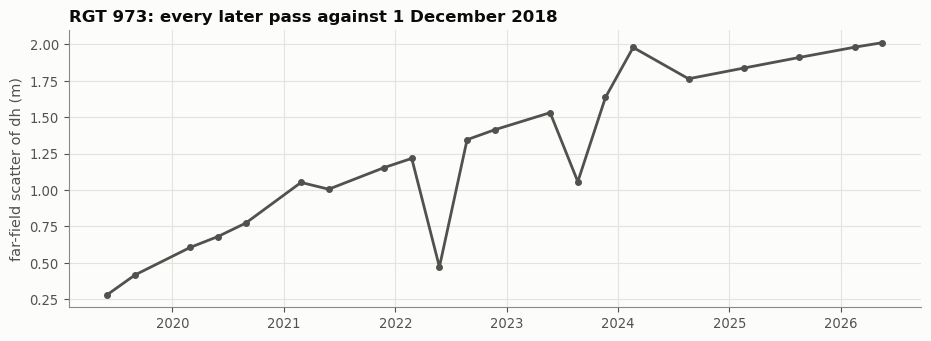

In [13]:
zrows = []
for c in sorted(atl[(atl.rgt == 973) & (atl.cycle >= 2)].cycle.unique()):
    d = it.pass_difference(atl, 973, 1, c, max_sep=600, far=far)
    if len(d) < 500:
        continue
    zrows.append(dict(time=d.time.iloc[0], cycle=c, far_sd=d[d.far].dh.std()))
zt = pd.DataFrame(zrows)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(zt.time, zt.far_sd, "o-", ms=4, color=ps.INK2)
ax.set(ylabel="far-field scatter of dh (m)", title="RGT 973: every later pass against 1 December 2018")
print(f"far-field scatter: {zt.far_sd.iloc[0]:.2f} m after {(zt.time.iloc[0] - pd.Timestamp('2018-12-01')).days} days, "
      f"{zt.far_sd.iloc[-1]:.2f} m after {(zt.time.iloc[-1] - pd.Timestamp('2018-12-01')).days / 365:.1f} years")

## 8. Summary, and comparison with Nivlisen

* **Lake years in the ICESat-2 era: 2019, 2025 and 2026.** These are long trough lakes, 20–40 km of which fall inside the 40 km window. 2020–2024 had at most small patches.
* **The plate matters more here than on Nivlisen.** The ice is thick (flexural length ~1–1.6 km) and the lake narrow (~1.6 km wide). An elastic plate would sink the lake floor by only a quarter to a third of the isostatic amount and sink the flanks by ~0.3 m at 1 km for a 2.3 m deep lake.
* **The water surface sits 0.1–0.35 m above the winter surface it replaced, over ~2 m of water.** This is what local isostasy predicts for new water (+0.06 m), not a rigid shelf (+2 m) or an elastic plate (+1.3–1.5 m). But here it is equally what an old, frozen lake melting out in place would do. The trough floor holds earlier lakes' ice under snow, so the test is not conclusive.
* **No sag beside the lake above ~0.2 m in any lake year.** Either little of the water was new load (most of it melted in place or arrived slowly), or the plate is close to relaxed, so it carries no load sideways. Both are unlike the instantaneous elastic plate.
* **Fast flow limits ICESat-2 here.** Six-month differences carry ±0.5 m of advected topography, and multi-year differences up to ~2 m, so persistent signals like Nivlisen's cannot be followed.

**Comparison with Nivlisen.** Nivlisen gives the cleaner experiment. There, in January 2020, water ~8 m deep (bed seen by ATL03) covered ground that had been dry snow nine months earlier. Its surface lay within 0.2 m of the old snow surface, and its shores sank 1–2 m. That is near-isostatic sinking under a genuinely new load, plus extra lowering at the shore. At the CTL the same test gives the same near-zero offset, but the lake re-forms each year on its own frozen predecessor, so the offset cannot be pinned on sinking.

**Next steps.**

* Lagrangian differencing (shifting each earlier pass by the ice velocity) would remove the advected topography and let the 2019, 2025 and 2026 loads be followed over years.
* A mass budget for the lake from its catchment's melt (RACMO/MAR) would show how much of each year's water is new load.
* Sentinel-1 could show whether the trough floor still holds liquid water or ice before each melt season.